# Multiscale DiT (ours)

A DiT-L/2 restoration network (24 blocks, hidden size 1024, patch size 2, 457 M parameters) trained in the
cold-diffusion setting. At level $t$ the input is the field continued $2.5\,t$ m upward, and the network
predicts the ground-level field. Weights: `weights/multiscale_dit.pth` (199k updates).

**Evaluation protocol (all notebooks).** The 10 synthetic test grids (32 × 32 nodes, 50 m spacing) are
scaled to [-1, 1] per grid. PSNR, SSIM, relative error (RE) and RMSE are computed on the central 24 × 24
window and reported as mean ± standard deviation (ddof = 0) over the 10 grids. Networks run in full FP32
with deterministic cuDNN (set when `gravdc` is imported, see `gravdc/precision.py`).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # make the gravdc package importable

import numpy as np
import torch

from gravdc import evaluate, format_summary, load_model, load_test_set, save_result, summarize
from gravdc.plotting import show_reconstruction
from gravdc.table2 import compare

DATA_DIR = "../data/test"
RESULTS_DIR = "../results"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.9.0+cu128


## Data
The forward model is the multiscale operator $A$: 40 successive upward continuations of 2.5 m (100 m in
total), each with zero padding to 36 × 36 and cropping back to 32 × 32. The observation is
$y = x_{40} = A^{40} x_0$.

In [2]:
from gravdc import MultiscaleOperator
from gravdc.sampling import multiscale_dc

names, x = load_test_set(DATA_DIR)
x = x.to(device)
A = MultiscaleOperator(steps=40, step=2.5, device=device)
y = A(x)
print(len(names), "grids:", names)

10 grids: ['data11.mat', 'data111.mat', 'data211.mat', 'data311.mat', 'data411.mat', 'data511.mat', 'data611.mat', 'data711.mat', 'data811.mat', 'data911.mat']


## Model and inference
`multiscale_dc` runs the restoration network $R(x_t, t)$ from $t = 40$ down to $1$:

* **Single-shot**: $\hat x_0 = R(y, 40)$, one network evaluation.
* **Stabilized DC**: $x_{t-1} = x_t - A^{t}R(x_t,t) + A^{t-1}R(x_t,t)$.
* **Recursive DC**: $x_{t-1} = A^{t-1}R(x_t,t)$.

In [3]:
model = load_model("multiscale_dit", device)
recs = {routine: multiscale_dc(model, y, A, routine) for routine in ['single-shot', 'stabilized']}

## Metrics

In [4]:
LABEL = {"single-shot": "Single-shot", "stabilized": "Stabilized DC", "recursive": "Recursive DC"}
for routine, x_hat in recs.items():
    row = f"Multiscale DiT ({LABEL[routine]})"
    per_image = evaluate(x, x_hat)
    compare(row, summarize(per_image))
    save_result(row, per_image, names, RESULTS_DIR)

Multiscale DiT (Single-shot)
  metric             this run              Table 2
  PSNR       60.1563 ± 4.4481     60.1563 ± 4.4481  ✓
  SSIM        0.9998 ± 0.0003      0.9998 ± 0.0003  ✓
  RE          0.0033 ± 0.0020      0.0033 ± 0.0020  ✓
  RMSE        0.0023 ± 0.0017      0.0023 ± 0.0017  ✓
Multiscale DiT (Stabilized DC)
  metric             this run              Table 2
  PSNR       64.7164 ± 6.6262     64.7164 ± 6.6262  ✓
  SSIM        0.9999 ± 0.0001      0.9999 ± 0.0001  ✓
  RE          0.0023 ± 0.0022      0.0023 ± 0.0022  ✓
  RMSE        0.0017 ± 0.0018      0.0017 ± 0.0018  ✓


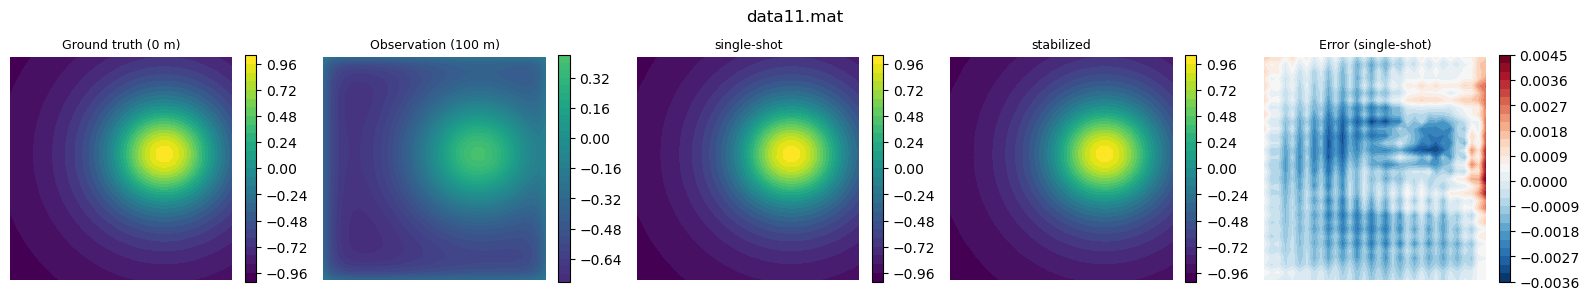

In [5]:
k = 0
show_reconstruction(x[k], y[k], {name: rec[k] for name, rec in recs.items()}, title=names[k])